In [17]:
# 1. Mengimpor library standar untuk manipulasi data dan angka
import pandas as pd
import numpy as np

# 2. Mengimpor library untuk visualisasi grafik (Plotting)
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Mengimpor alat dari Scikit-Learn untuk Machine Learning
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer

# 4. Pengaturan tambahan
import warnings
warnings.filterwarnings('ignore') # Agar peringatan (warning) merah tidak muncul
sns.set_theme(style="whitegrid") # Mempercantik latar belakang grafik

print("Tahap 1 Selesai: Semua library berhasil dimuat!")

Tahap 1 Selesai: Semua library berhasil dimuat!


In [18]:
# 1. Membaca dataset
df = pd.read_csv('pelayanan_umum.csv')

# Menyimpan versi asli untuk keperluan label grafik nanti
df_asli = df.copy()

# 2. Memecah 'tekanan_darah' (contoh: '120/80' menjadi sistolik=120, diastolik=80)
if 'tekanan_darah' in df.columns:
    # Memperbaiki penulisan garis miring yang salah (jika ada)
    df['tekanan_darah'] = df['tekanan_darah'].astype(str).str.replace(r'\\', '/', regex=True)
    # Memecah menjadi dua kolom berdasarkan '/'
    bp = df['tekanan_darah'].str.split('/', expand=True)
    df['sistolik'] = pd.to_numeric(bp[0], errors='coerce')
    df['diastolik'] = pd.to_numeric(bp[1], errors='coerce')
    # Membuang kolom tekanan darah lama yang berupa teks
    df = df.drop('tekanan_darah', axis=1)

# 3. Menangani Data Kosong (Imputasi)
# Untuk data angka: kita isi dengan nilai tengah (median)
kolom_numerik = ['suhu_tubuh', 'denyut_nadi', 'pernapasan', 'berat_badan', 'tinggi_badan', 'sistolik', 'diastolik']
for col in kolom_numerik:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col].fillna(df[col].median(), inplace=True)

# Untuk data teks: kita isi dengan kata 'Tidak_Diketahui'
kolom_teks = ['keluhan', 'pemeriksaan_fisik', 'diagnosis', 'tindakan', 'terapi', 'catatan', 'dokter_pemeriksa']
for col in kolom_teks:
    if col in df.columns:
        df[col].fillna('Tidak_Diketahui', inplace=True)

print("Tahap 2 Selesai: Data berhasil dibaca dan dibersihkan dari nilai kosong.")
display(df.head(3)) # Menampilkan 3 baris pertama

Tahap 2 Selesai: Data berhasil dibaca dan dibersihkan dari nilai kosong.


,id,id_pasien,tanggal_kunjungan,keluhan,pemeriksaan_fisik,suhu_tubuh,denyut_nadi,pernapasan,berat_badan,tinggi_badan,diagnosis,tindakan,terapi,catatan,dokter_pemeriksa,sistolik,diastolik
0,1,1,2024-06-01,SAKIT KEPALA,KONDISI UMUM BAIK,36.7,78.0,18.0,55.0,158.0,Migrain ringan,Observasi,Parasetamol,Tidak_Diketahui,dr. Neni,110.0,70.0
1,2,2,2024-06-02,DEMAM,KULIT TERASA PANAS,38.0,84.0,20.0,53.5,160.0,Infeksi virus,Pemberian cairan,Antipiretik,Tidak_Diketahui,dr. Ayu,120.0,80.0
2,3,3,2024-06-03,BATUK,TENGGOROKAN MERAH,37.2,82.0,18.0,60.0,162.0,ISPA,Nebu ringan,Sirup batuk,Tidak_Diketahui,dr. Rina,115.0,75.0


In [19]:
# Inisialisasi alat pengubah teks ke angka
le = LabelEncoder()

# Daftar kolom yang berisi teks
kolom_teks = ['keluhan', 'pemeriksaan_fisik', 'diagnosis', 'tindakan', 'terapi', 'catatan', 'dokter_pemeriksa']

# Proses pengubahan
for col in kolom_teks:
    if col in df.columns:
        # Mengubah teks menjadi angka
        df[col] = le.fit_transform(df[col].astype(str))

# Opsional: Membuang kolom yang tidak bisa di-cluster (misal tanggal dan ID)
kolom_dibuang = ['tanggal_kunjungan', 'id_pasien', 'id']
for col in kolom_dibuang:
    if col in df.columns:
        df = df.drop(col, axis=1)

print("Tahap 3 Selesai: Seluruh data telah menjadi format numerik.")
display(df.head(3))

Tahap 3 Selesai: Seluruh data telah menjadi format numerik.


,keluhan,pemeriksaan_fisik,suhu_tubuh,denyut_nadi,pernapasan,berat_badan,tinggi_badan,diagnosis,tindakan,terapi,catatan,dokter_pemeriksa,sistolik,diastolik
0,169,2,36.7,78.0,18.0,55.0,158.0,40,18,182,0,5,110.0,70.0
1,29,3,38.0,84.0,20.0,53.5,160.0,33,19,20,0,2,120.0,80.0
2,7,9,37.2,82.0,18.0,60.0,162.0,32,17,219,0,6,115.0,75.0


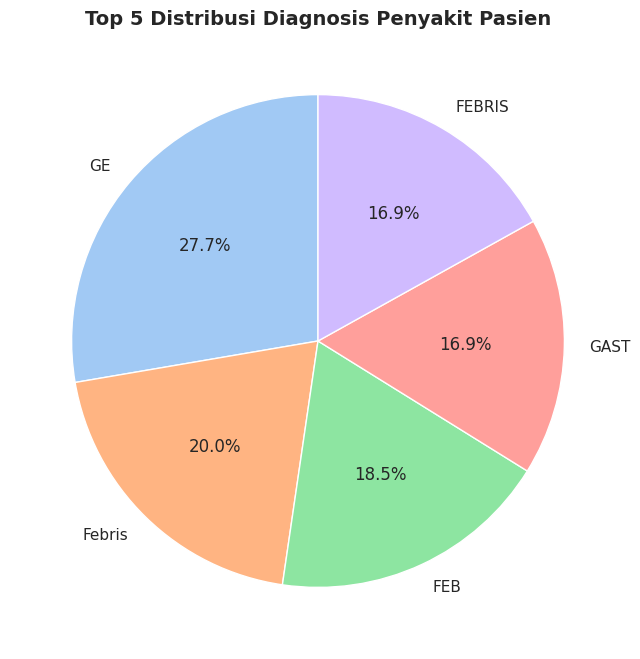

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# VISUALISASI 1: PIE CHART DIAGNOSIS TERBANYAK
# ==========================================
# Mengambil 5 diagnosis terbanyak menggunakan data yang belum di-encode (df_asli)
top_diagnosis = df_asli['diagnosis'].value_counts().head(5)

# Membuat kanvas grafik
plt.figure(figsize=(8, 8))

# Menggambar Pie Chart
plt.pie(
    top_diagnosis,
    labels=top_diagnosis.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('pastel')
)

plt.title('Top 5 Distribusi Diagnosis Penyakit Pasien', fontsize=14, fontweight='bold')
plt.show()


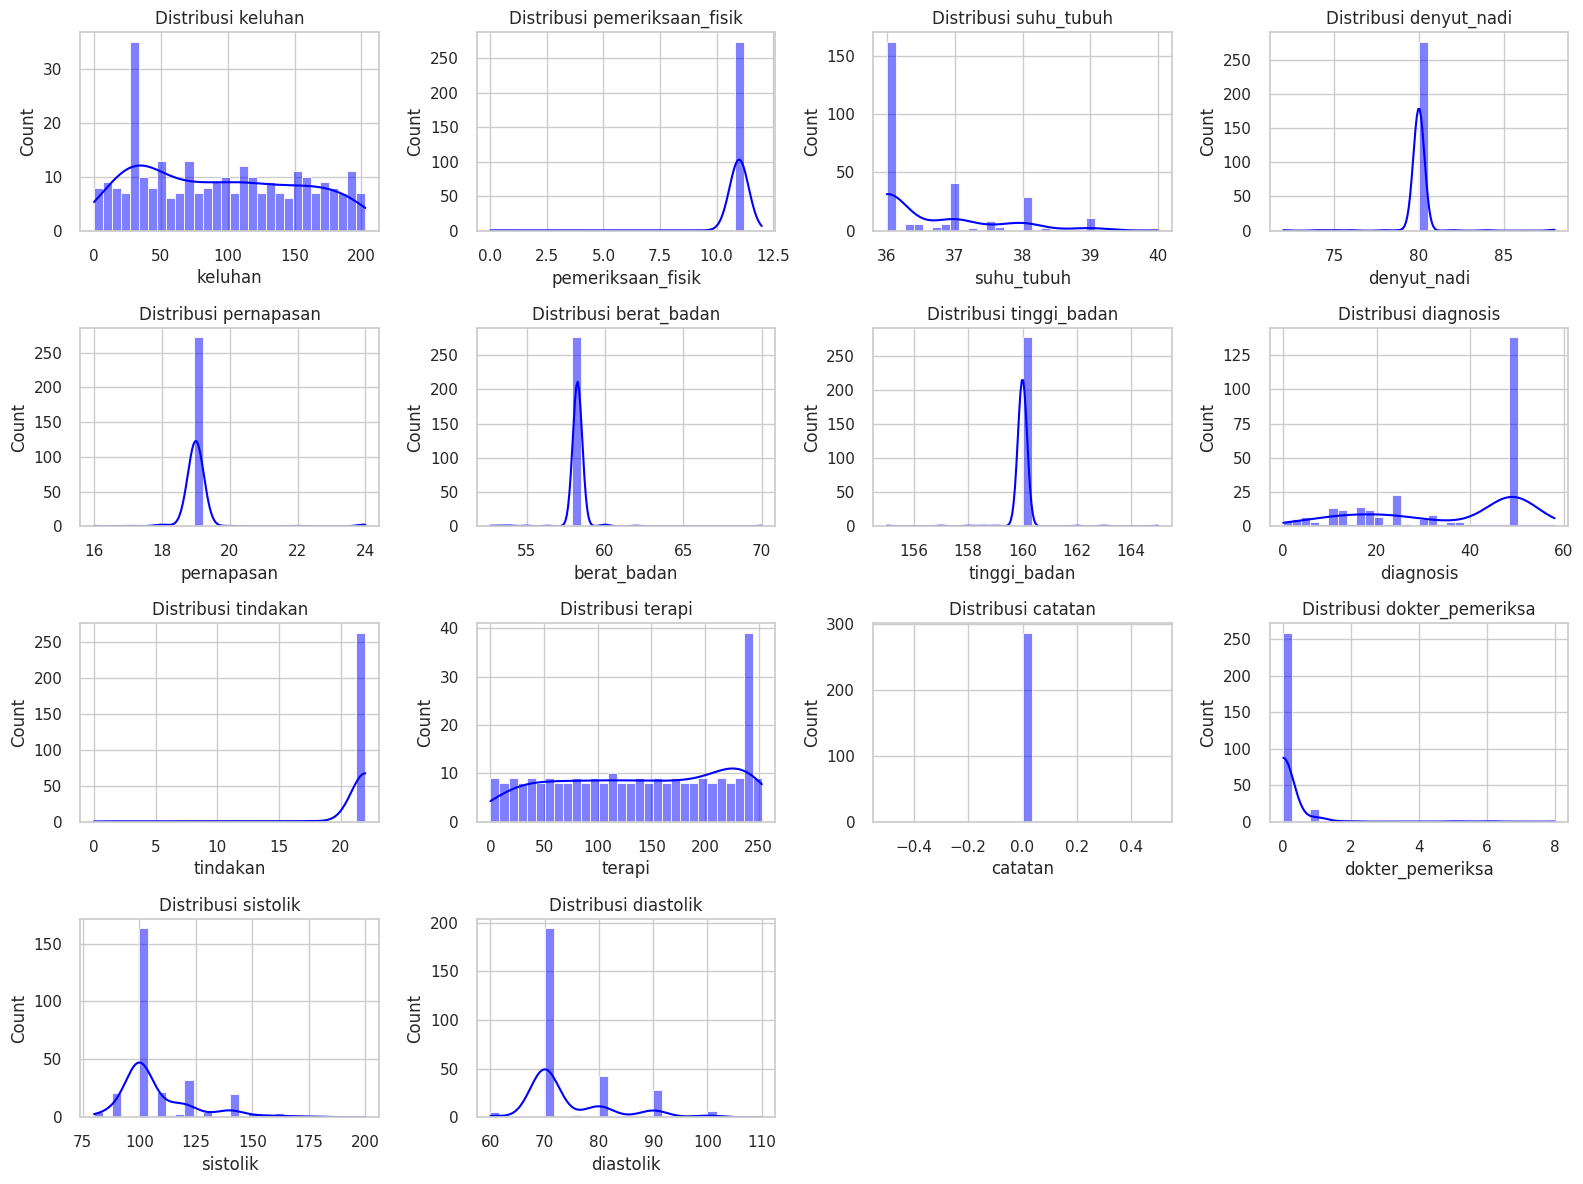

In [21]:


# ==========================================
# VISUALISASI 2: DISTRIBUSI FITUR NUMERIK (HISTOGRAM)
# ==========================================
# Memilih hanya kolom-kolom yang berisi angka (numerik) dari variabel 'df'
num_features = df.select_dtypes(include=[np.number])

# Membuat kanvas yang besar agar cukup untuk banyak grafik sekaligus
plt.figure(figsize=(16, 12)) # Diperbarui untuk grid 4x4

# Melakukan perulangan untuk membuat histogram dari masing-masing kolom angka
for i, column in enumerate(num_features.columns, 1):
    # Mengatur letak grafik dalam format grid (4 baris, 4 kolom) - Diperbarui dari 3,4
    plt.subplot(4, 4, i)

    # Menggambar histogram dengan kurva kepadatan (KDE)
    sns.histplot(df[column], bins=30, kde=True, color='blue')
    plt.title(f'Distribusi {column}')

# Mengatur jarak antar grafik agar tidak tumpang tindih
plt.tight_layout()
plt.show()


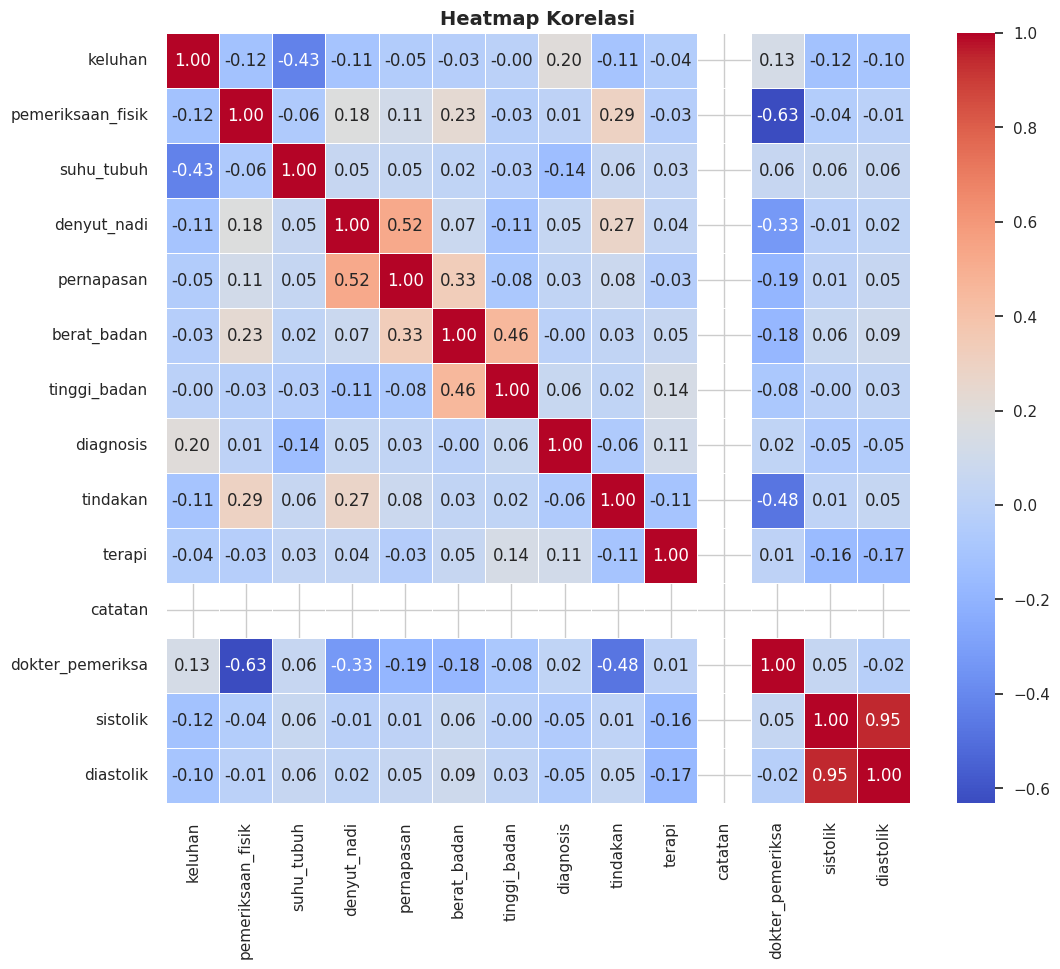

In [22]:

# ==========================================
# VISUALISASI 3: HEATMAP KORELASI FITUR NUMERIK
# ==========================================
# Heatmap korelasi untuk fitur numerik
plt.figure(figsize=(12, 10))
correlation_matrix = num_features.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi', fontsize=14, fontweight='bold')
plt.show()

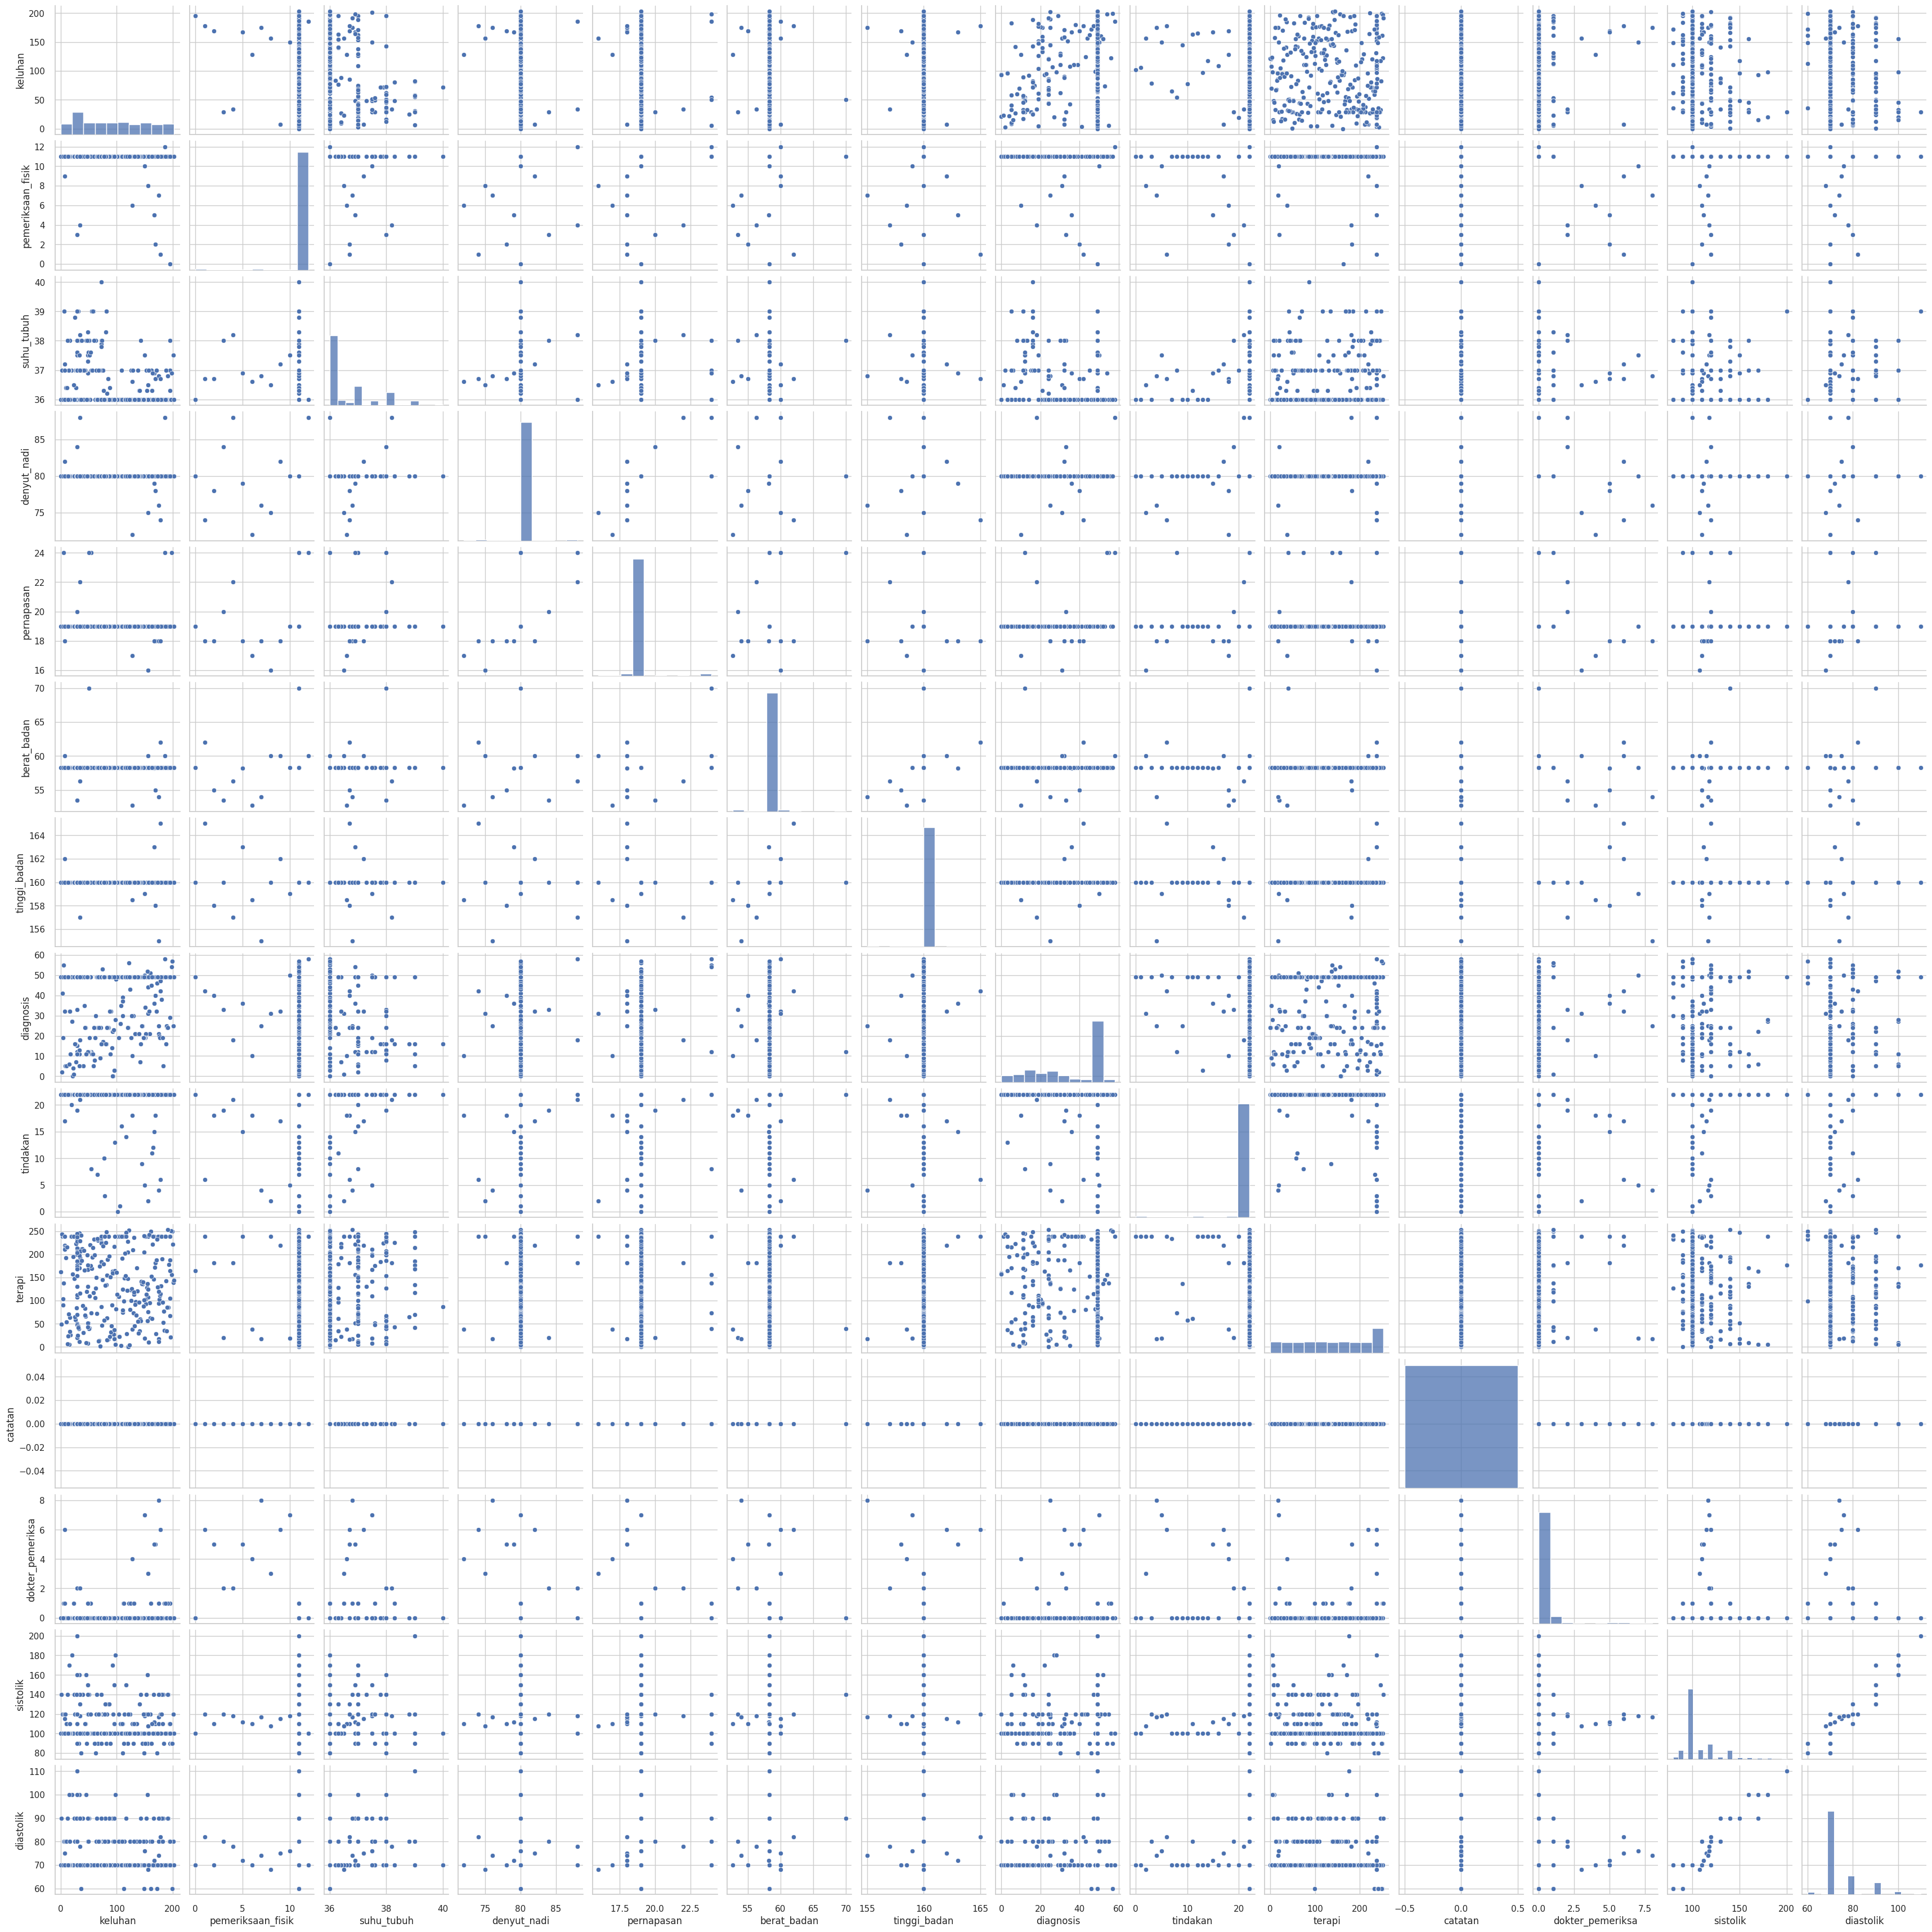

In [23]:
# Pairplot untuk fitur numerik
sns.pairplot(num_features)
plt.show()

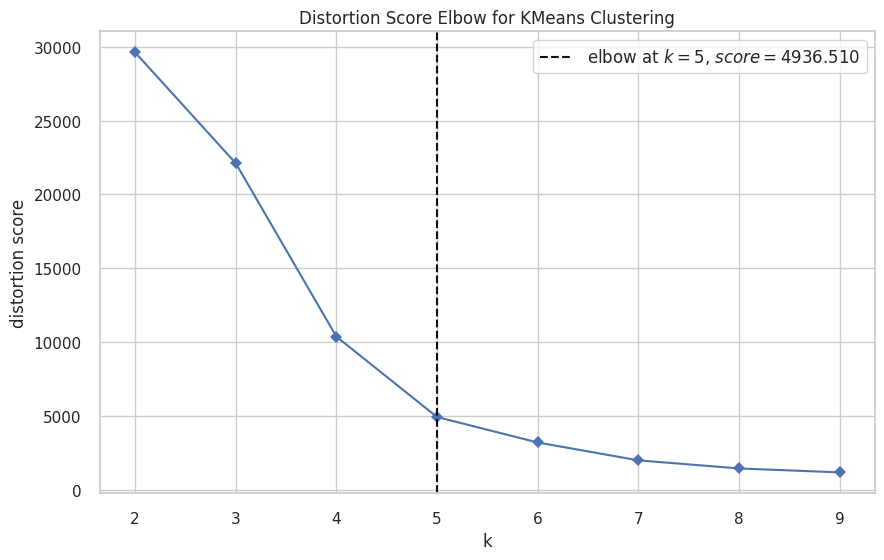

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [24]:
# 1. Memilih fitur untuk dikelompokkan
# X adalah matriks yang berisi Suhu Tubuh dan Tekanan Darah Sistolik
X = df[['suhu_tubuh', 'sistolik']].values

# 2. Menggunakan KElbowVisualizer untuk mencari jumlah klaster (k) terbaik
model_kmeans = KMeans(random_state=42)

# Menguji klaster dari 2 hingga 10
visualizer = KElbowVisualizer(model_kmeans, k=(2, 10), timings=False)

plt.figure(figsize=(10, 6))
visualizer.fit(X) # Proses perhitungan
visualizer.show() # Menampilkan grafik

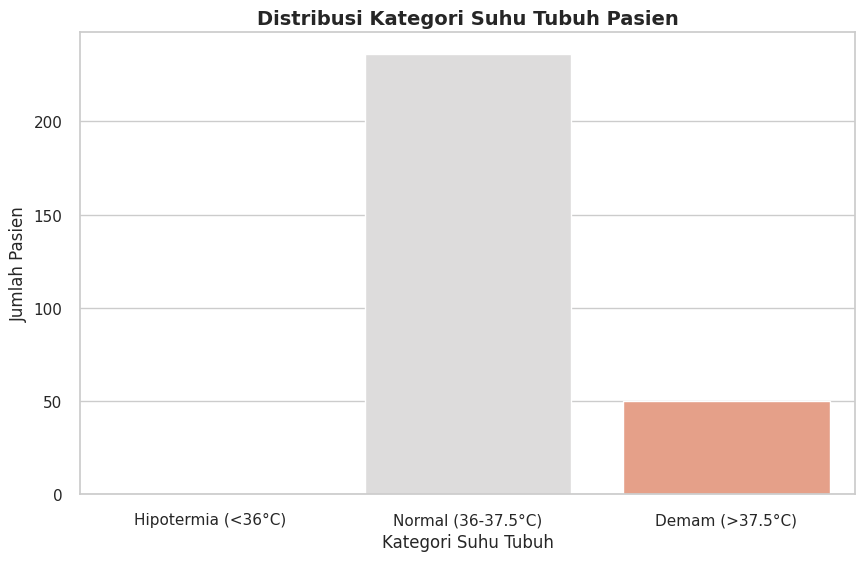

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. PENGELOMPOKAN SUHU TUBUH
# ==========================================
# Mengelompokkan suhu tubuh pasien ke dalam kategori medis dan menghitung jumlahnya
suhu_hipo = df.suhu_tubuh[df.suhu_tubuh < 36.0]
suhu_normal = df.suhu_tubuh[(df.suhu_tubuh >= 36.0) & (df.suhu_tubuh <= 37.5)]
suhu_demam = df.suhu_tubuh[df.suhu_tubuh > 37.5]

# Menyusun data untuk plotting
x_suhu = ["Hipotermia (<36°C)", "Normal (36-37.5°C)", "Demam (>37.5°C)"]
y_suhu = [len(suhu_hipo.values), len(suhu_normal.values), len(suhu_demam.values)]

# Membuat bar chart untuk distribusi suhu tubuh
plt.figure(figsize=(10, 6))
sns.barplot(x=x_suhu, y=y_suhu, palette="coolwarm")
plt.title("Distribusi Kategori Suhu Tubuh Pasien", fontsize=14, fontweight='bold')
plt.xlabel("Kategori Suhu Tubuh")
plt.ylabel("Jumlah Pasien")
plt.show()

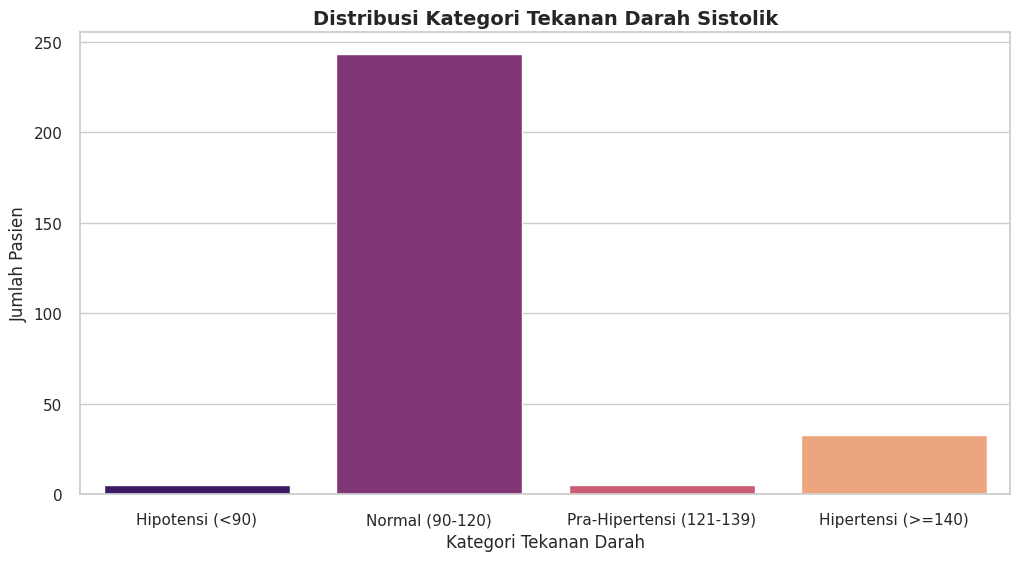

In [26]:
# ==========================================
# 2. PENGELOMPOKAN TEKANAN DARAH SISTOLIK
# ==========================================
# Mengelompokkan tekanan darah atas (sistolik) ke dalam kategori medis
tensi_rendah = df.sistolik[df.sistolik < 90]
tensi_normal = df.sistolik[(df.sistolik >= 90) & (df.sistolik <= 120)]
tensi_pra = df.sistolik[(df.sistolik > 120) & (df.sistolik <= 139)]
tensi_tinggi = df.sistolik[df.sistolik >= 140]

# Menyusun data untuk plotting
x_tensi = ["Hipotensi (<90)", "Normal (90-120)", "Pra-Hipertensi (121-139)", "Hipertensi (>=140)"]
y_tensi = [len(tensi_rendah.values), len(tensi_normal.values), len(tensi_pra.values), len(tensi_tinggi.values)]

# Membuat bar chart
plt.figure(figsize=(12, 6))
sns.barplot(x=x_tensi, y=y_tensi, palette="magma")
plt.title("Distribusi Kategori Tekanan Darah Sistolik", fontsize=14, fontweight='bold')
plt.xlabel("Kategori Tekanan Darah")
plt.ylabel("Jumlah Pasien")
plt.show()

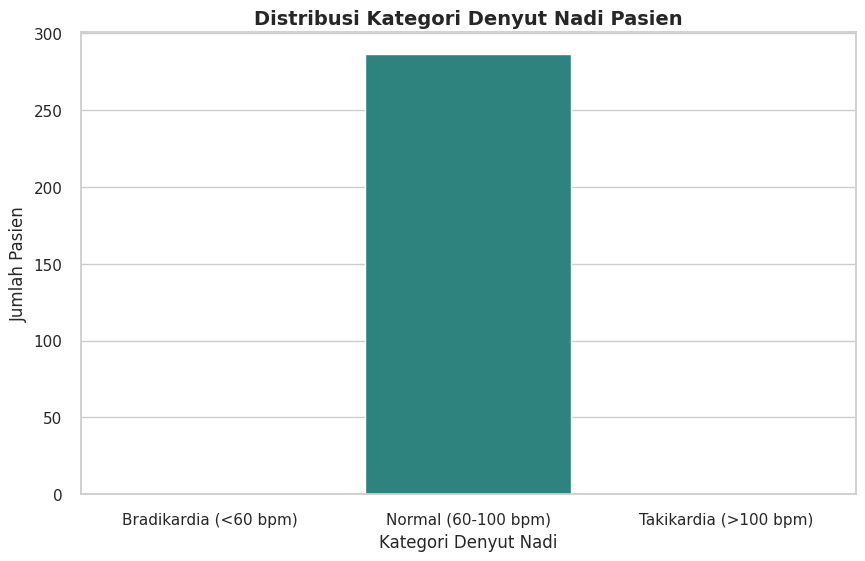

In [27]:
# ==========================================
# 3. PENGELOMPOKAN DENYUT NADI (Heart Rate)
# ==========================================
# Mengelompokkan denyut nadi per menit (bpm)
nadi_lambat = df.denyut_nadi[df.denyut_nadi < 60]
nadi_normal = df.denyut_nadi[(df.denyut_nadi >= 60) & (df.denyut_nadi <= 100)]
nadi_cepat = df.denyut_nadi[df.denyut_nadi > 100]

# Menyusun data
x_nadi = ["Bradikardia (<60 bpm)", "Normal (60-100 bpm)", "Takikardia (>100 bpm)"]
y_nadi = [len(nadi_lambat.values), len(nadi_normal.values), len(nadi_cepat.values)]

# Membuat bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=x_nadi, y=y_nadi, palette="viridis")
plt.title("Distribusi Kategori Denyut Nadi Pasien", fontsize=14, fontweight='bold')
plt.xlabel("Kategori Denyut Nadi")
plt.ylabel("Jumlah Pasien")
plt.show()

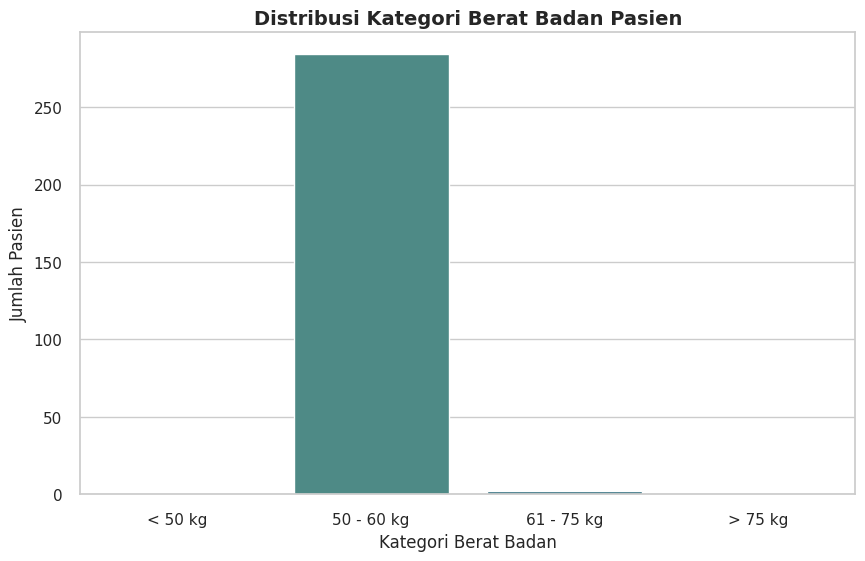

In [28]:
# ==========================================
# 4. PENGELOMPOKAN BERAT BADAN
# ==========================================
# Mengelompokkan berat badan menjadi beberapa rentang berat (kg)
bb_kurang50 = df.berat_badan[df.berat_badan < 50]
bb_50_60 = df.berat_badan[(df.berat_badan >= 50) & (df.berat_badan <= 60)]
bb_61_75 = df.berat_badan[(df.berat_badan >= 61) & (df.berat_badan <= 75)]
bb_lebih75 = df.berat_badan[df.berat_badan > 75]

# Menyusun data
x_bb = ["< 50 kg", "50 - 60 kg", "61 - 75 kg", "> 75 kg"]
y_bb = [len(bb_kurang50.values), len(bb_50_60.values), len(bb_61_75.values), len(bb_lebih75.values)]

# Membuat bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=x_bb, y=y_bb, palette="crest")
plt.title("Distribusi Kategori Berat Badan Pasien", fontsize=14, fontweight='bold')
plt.xlabel("Kategori Berat Badan")
plt.ylabel("Jumlah Pasien")
plt.show()

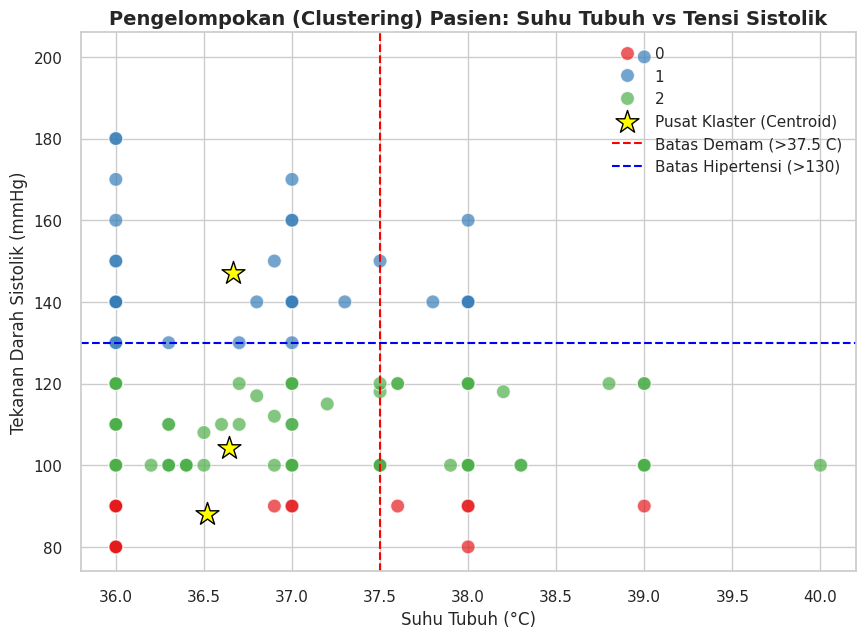

Skor Silhouette untuk model ini adalah: 0.591
Skor mendekati 1 berarti kelompok terpisah dengan sangat baik.

HASIL INFORMASI (INSIGHT) DINAMIS BERDASARKAN K-MEANS CENTROID
Algoritma K-Means telah membagi pasien ke dalam 3 kelompok risiko utama berdasarkan postur matematis titik tengahnya.

➔ CLUSTER 1 (Dihuni oleh 26 pasien)
   • Titik Pusat (Centroid) : Suhu 36.52 °C, Tensi Sistolik 88.08 mmHg
   • Profil Medis Mesin     : Menunjukkan kelompok pasien dengan suhu tubuh yang Normal dan tekanan darah Normal/Stabil.
   • Insight & Rekomendasi  : Kelompok pasien relatif aman (Kondisi Vital Stabil). Pasien di kelompok ini dapat mengikuti antrean reguler untuk mendapatkan terapi rawat jalan sesuai keluhan utamanya.
--------------------------------------------------------------------------------
➔ CLUSTER 2 (Dihuni oleh 38 pasien)
   • Titik Pusat (Centroid) : Suhu 36.67 °C, Tensi Sistolik 147.11 mmHg
   • Profil Medis Mesin     : Menunjukkan kelompok pasien dengan suhu tubuh yang Normal dan

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# ==========================================
# 5. K-MEANS CLUSTERING & ANALISIS DINAMIS CENTROID
# ==========================================
# Menyiapkan fitur X (Suhu Tubuh vs Tensi Sistolik)
X = df[['suhu_tubuh', 'sistolik']].values

# Berdasarkan metode Elbow, asumsikan kita pilih 3 klaster
k_optimal = 3

# Melatih model K-Means
kmeans = KMeans(n_clusters=k_optimal, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X)

# Menyimpan hasil klaster ke dataframe (bisa menggunakan df asli jika masih ada, di sini kita gunakan df)
df['Cluster_Risiko'] = y_kmeans

# Visualisasi Scatter Plot
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y_kmeans, palette='Set1', s=100, alpha=0.7)

# Menggambar titik pusat (Centroid) dari tiap kelompok
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=300, c='yellow', marker='*', edgecolor='black', label='Pusat Klaster (Centroid)'
)

# Menambahkan garis batas normal medis (hanya sebagai panduan visual)
plt.axvline(x=37.5, color='red', linestyle='--', label='Batas Demam (>37.5 C)')
plt.axhline(y=130, color='blue', linestyle='--', label='Batas Hipertensi (>130)')

plt.title('Pengelompokan (Clustering) Pasien: Suhu Tubuh vs Tensi Sistolik', fontsize=14, fontweight='bold')
plt.xlabel('Suhu Tubuh (°C)')
plt.ylabel('Tekanan Darah Sistolik (mmHg)')
plt.legend()
plt.show()

# Evaluasi Skor Siluet
score = silhouette_score(X, y_kmeans)
print(f"Skor Silhouette untuk model ini adalah: {score:.3f}")
print("Skor mendekati 1 berarti kelompok terpisah dengan sangat baik.\n")

# --- MENCETAK HASIL INFORMASI (INSIGHT) SECARA DINAMIS ---
print("="*80)
print("HASIL INFORMASI (INSIGHT) DINAMIS BERDASARKAN K-MEANS CENTROID")
print("="*80)
print(f"Algoritma K-Means telah membagi pasien ke dalam {k_optimal} kelompok risiko utama berdasarkan postur matematis titik tengahnya.\n")

for i in range(k_optimal):
    # Mengambil nilai kordinat centroid
    suhu_centroid = kmeans.cluster_centers_[i, 0]
    tensi_centroid = kmeans.cluster_centers_[i, 1]

    # Menghitung jumlah pasien di dalam cluster tersebut
    jml_pasien = len(X[y_kmeans == i])

    # Logika deteksi kategori secara otomatis
    kategori_suhu = "Demam" if suhu_centroid > 37.5 else "Normal"
    kategori_tensi = "Hipertensi/Tinggi" if tensi_centroid >= 130 else "Normal/Stabil"

    print(f"➔ CLUSTER {i+1} (Dihuni oleh {jml_pasien} pasien)")
    print(f"   • Titik Pusat (Centroid) : Suhu {suhu_centroid:.2f} °C, Tensi Sistolik {tensi_centroid:.2f} mmHg")
    print(f"   • Profil Medis Mesin     : Menunjukkan kelompok pasien dengan suhu tubuh yang {kategori_suhu} dan tekanan darah {kategori_tensi}.")

    # Menampilkan saran (actionable insight) yang sangat spesifik
    print("   • Insight & Rekomendasi  : ", end="")
    if kategori_suhu == "Demam" and kategori_tensi == "Hipertensi/Tinggi":
        print("KELOMPOK KRITIS! Ini adalah pasien berisiko tinggi di mana demam memicu lonjakan tekanan darah (atau sebaliknya). Prioritaskan penanganan medis gawat darurat dan cegah komplikasi kejang/kardiovaskular.")
    elif kategori_suhu == "Demam":
        print("Fokus utama pada manajemen infeksi. Perawat dapat mendahulukan tes darah lab atau pemberian terapi antipiretik untuk kelompok ini sebelum tekanan darah mereka ikut bergejolak.")
    elif kategori_tensi == "Hipertensi/Tinggi":
        print("Kelompok berisiko pada sistem peredaran darah tanpa disertai infeksi/demam. Fokus pada penanganan hipertensi rutin, manajemen stres, dan edukasi pola makan.")
    else:
        print("Kelompok pasien relatif aman (Kondisi Vital Stabil). Pasien di kelompok ini dapat mengikuti antrean reguler untuk mendapatkan terapi rawat jalan sesuai keluhan utamanya.")

    print("-" * 80)

## Hierarchical Clustering

Hierarchical clustering is another method for grouping data points. It builds a hierarchy of clusters, represented as a tree-like diagram called a dendrogram. This visualization helps to understand the relationships between clusters at different levels of similarity.

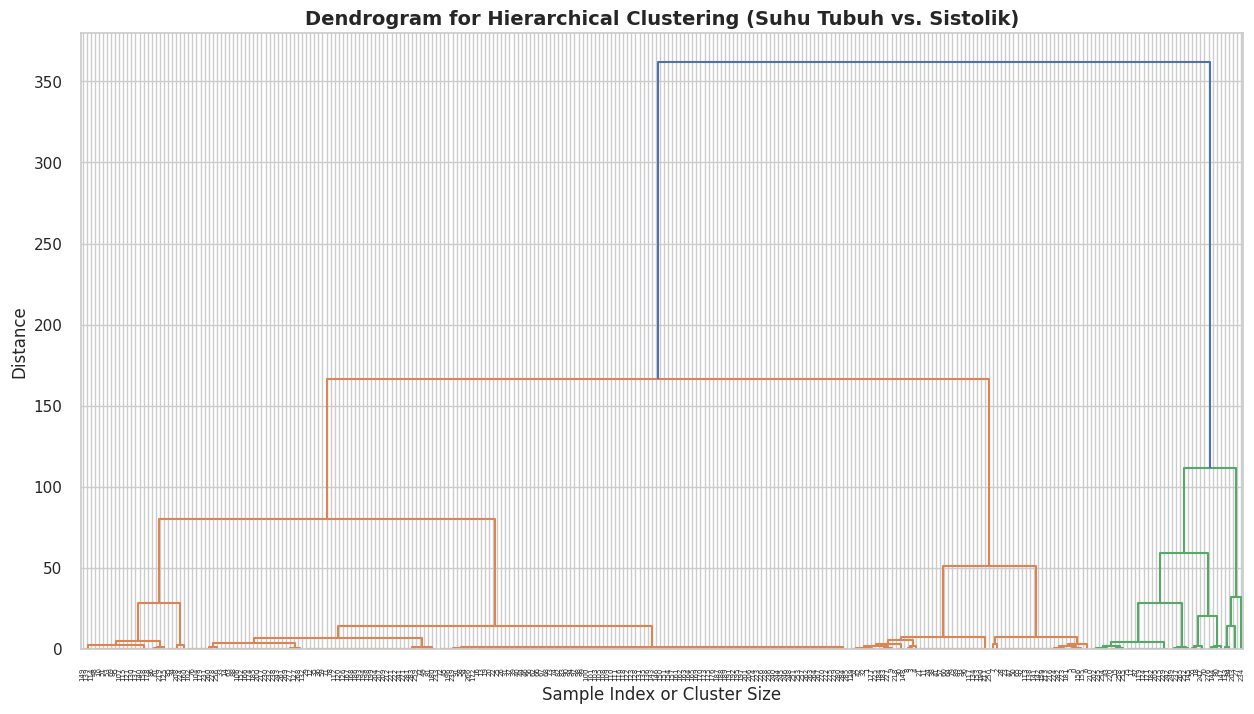

In [30]:
# Import necessary libraries for hierarchical clustering
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

# Use the same features as K-Means for consistency
X = df[['suhu_tubuh', 'sistolik']].values

# Calculate the distance matrix
dist_matrix = pdist(X)

# Perform hierarchical clustering using the 'ward' method
# 'ward' minimizes the variance of the clusters being merged
linked_data = linkage(dist_matrix, method='ward')

# Plot the dendrogram
plt.figure(figsize=(15, 8))
dendrogram(
    linked_data,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True
)
plt.title('Dendrogram for Hierarchical Clustering (Suhu Tubuh vs. Sistolik)', fontsize=14, fontweight='bold')
plt.xlabel('Sample Index or Cluster Size')
plt.ylabel('Distance')
plt.show()